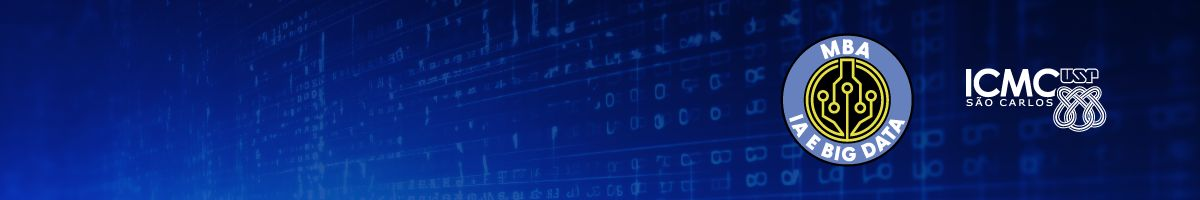

<br><br>
<div style="font-family: Arial; font-size: 16px;  color: #000080;">  
    
# Estatística na Ciência da Computação Experimental e R

por **Mariana Cúri** e **Cibele Russo**

**ICMC/USP - São Carlos SP**



<div style="font-family: Arial; font-size: 16px;  color: #000080;">  
    
# Testes de hipóteses não paramétricos



<div style="font-family: Arial; font-size: 16px;  color: #000080;">  

## Teste Qui-quadrado para associação de variáveis



<div style="font-family: Arial; font-size: 16px;  color: #000080;">  

### Exemplo dados de música

In [1]:
import pandas as pd
from scipy.stats import chi2_contingency


# Leitura dos dados de música
df = pd.read_csv('https://raw.githubusercontent.com/cibelerusso/Datasets/main/Music_DB.csv', decimal=',')



In [2]:
df.columns

Index(['Energia', 'Ao_vivo', 'Tempo', 'Falado', 'Orgânico', 'Instrumental',
       'Compasso', 'Dançabilidade', 'Tom', 'Duração', 'Força', 'Positividade',
       'Modo', 'Tipo', 'Music_id', 'Playlist_name', 'Album_name', 'Artista',
       'Music_name'],
      dtype='object')

In [3]:
# Tabela de frequências absolutas

tab = pd.crosstab(index=df['Tom'], columns=df['Modo'], margins='columns', margins_name='Total')

tab

Modo,0,1,Total
Tom,,,
0,216,811,1027
1,246,557,803
2,176,605,781
3,94,209,303
4,272,324,596
5,242,433,675
6,210,249,459
7,192,635,827
8,117,395,512


In [4]:
df

,Energia,Ao_vivo,Tempo,Falado,Orgânico,Instrumental,Compasso,Dançabilidade,Tom,Duração,Força,Positividade,Modo,Tipo,Music_id,Playlist_name,Album_name,Artista,Music_name
0,0.964,0.1060,167.024,0.0644,0.000071,0.038700,4,0.392,10,200547,0.599722,0.269,0,audio_features,0faXHILILebCGnJBPU6KJJ,Angry,Phobia (Clean Version),Breaking Benjamin,The Diary of Jane - Single Version
1,0.955,0.3800,107.984,0.0653,0.000165,0.000014,4,0.533,8,216733,0.652529,0.550,1,audio_features,2yXyz4NLTZx9CLdXfLTp5E,Angry,Dear Agony,Breaking Benjamin,I Will Not Bow
2,0.939,0.6230,150.184,0.1130,0.000220,0.000000,4,0.524,9,184867,0.631393,0.661,1,audio_features,1Vej0qeQ3ioKwpI6FUbRv1,Angry,Hybrid Theory (Bonus Edition),Linkin Park,Papercut
3,0.969,0.0787,95.136,0.0491,0.001400,0.000001,4,0.492,9,157333,0.601243,0.538,1,audio_features,3K4HG9evC7dg3N0R9cYqk4,Angry,Hybrid Theory (Bonus Edition),Linkin Park,One Step Closer
4,0.970,0.0994,94.952,0.2120,0.030000,0.000000,4,0.512,8,200240,0.639293,0.427,0,audio_features,5egqKwgK5r5rvGD1LrtR7J,Angry,Hybrid Theory (Bonus Edition),Linkin Park,Points of Authority
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7697,0.920,0.0562,100.007,0.0369,0.002120,0.000008,4,0.544,4,272013,0.448745,0.683,0,audio_features,0tJipFCATY8M2WWXXNyJ9p,Nervous,Unholy Savior,Battle Beast,Touch In The Night
7698,0.941,0.0852,124.977,0.0337,0.000026,0.000025,4,0.525,9,177347,0.665350,0.541,0,audio_features,1VKTwfRivDO6neMF6mm9QZ,Nervous,Battle Beast,Battle Beast,Out on the Streets
7699,0.933,0.1740,82.807,0.0774,0.000904,0.000008,4,0.445,4,279587,0.542875,0.517,0,audio_features,3bGMBNy2fhhKYF1haK6pYg,Nervous,Bringer of Pain,Battle Beast,Beyond the Burning Skies
7700,0.886,0.1120,110.021,0.0353,0.000091,0.000431,4,0.506,2,328787,0.630376,0.200,0,audio_features,6NTEk76W6mraayMZV5zhhR,Nervous,Battle Beast,Battle Beast,Into the Heart of Danger


In [5]:
import pandas as pd
from scipy.stats import chi2_contingency

# Criando a tabela de contingência
tab = pd.crosstab(index=df['Tom'], columns=df['Modo'], margins=True, margins_name='Total')

# Realizando o teste qui-quadrado
chi2, p, dof, expected = chi2_contingency(tab.iloc[:-1, :-1])

# Exibindo os resultados
print(f"Qui-quadrado: {chi2}")
print(f"Valor p: {p}")
print(f"Graus de liberdade: {dof}")
print("Frequências esperadas:")
print(expected)


# Interpretação
alpha = 0.05
if p < alpha:
    print("\nRejeita a hipótese nula: Existe associação entre Tom e Modo")
else:
    print("\nNão rejeita a hipótese nula: Não existe associação entre Tom e Modo.")


Qui-quadrado: 383.9268476499283
Valor p: 1.5747719278373998e-75
Graus de liberdade: 11
Frequências esperadas:
[[339.35536224 687.64463776]
 [265.33822384 537.66177616]
 [258.06868346 522.93131654]
 [100.12139704 202.87860296]
 [196.93845754 399.06154246]
 [223.04271618 451.95728382]
 [151.669047   307.330953  ]
 [273.26863152 553.73136848]
 [169.18203064 342.81796936]
 [236.59049598 479.40950402]
 [158.27772007 320.72227993]
 [173.14723448 350.85276552]]

Rejeita a hipótese nula: Existe associação entre Tom e Modo


In [6]:
import pandas as pd
from scipy.stats import chi2_contingency

# Criando a tabela de contingência
tab = pd.crosstab(index=df['Playlist_name'], columns=df['Modo'], margins=True, margins_name='Total')

tab

Modo,0,1,Total
Playlist_name,,,
Angry,214,321,535
Annoying,128,342,470
Boring,239,316,555
Calm,149,486,635
Excited,240,278,518
Happy,152,457,609
Nervous,236,398,634
Peaceful,253,580,833
Pleased,188,490,678


In [7]:

# Realizando o teste qui-quadrado
chi2, p, dof, expected = chi2_contingency(tab.iloc[:-1, :-1])

# Exibindo os resultados
print(f"Qui-quadrado: {chi2}")
print(f"Valor p: {p}")
print(f"Graus de liberdade: {dof}")
print("Frequências esperadas:")
print(expected)


# Interpretação
alpha = 0.05
if p < alpha:
    print("\nRejeita a hipótese nula: Existe associação entre Playlist_name e Modo.")
else:
    print("\nNão rejeita a hipótese nula: Não existe associação entre Playlist_name e Modo.")


Qui-quadrado: 158.15252644536412
Valor p: 3.199410186778573e-28
Graus de liberdade: 11
Frequências esperadas:
[[176.78200467 358.21799533]
 [155.30381719 314.69618281]
 [183.39067775 371.60932225]
 [209.82537003 425.17462997]
 [171.16463256 346.83536744]
 [201.23409504 407.76590496]
 [209.49493638 424.50506362]
 [275.25123345 557.74876655]
 [224.03401714 453.96598286]
 [277.56426902 562.43573098]
 [169.84289795 344.15710205]
 [291.11204882 589.88795118]]

Rejeita a hipótese nula: Existe associação entre Playlist_name e Modo.


<div style="font-family: Arial; font-size: 16px;  color: #000080;">  

## Exemplo computadores e eficiência


In [8]:
data = {
    'Eficiente': [80, 50],
    'Ineficiente': [20, 50]
}

df = pd.DataFrame(data, index=['Computador de Alto Desempenho', 'Computador Padrão'])

df


,Eficiente,Ineficiente
Computador de Alto Desempenho,80,20
Computador Padrão,50,50


In [9]:
print("Tabela de Contingência:\n", df)

# Teste qui-quadrado
chi2, p, dof, expected = chi2_contingency(df)

# Exibir os resultados
print("\nResultados do Teste Qui-Quadrado:")
print("Estatística qui-quadrado:", chi2)
print("Valor-p:", p)
print("Graus de liberdade:", dof)
print("Frequências esperadas:\n", expected)

# Interpretação
alpha = 0.05
if p < alpha:
    print("\nRejeita a hipótese nula: Existe associação entre o tipo de máquina e a eficiência do algoritmo.")
else:
    print("\nNão rejeita a hipótese nula: Não existe associação entre o tipo de máquina e a eficiência do algoritmo.")


Tabela de Contingência:
                                Eficiente  Ineficiente
Computador de Alto Desempenho         80           20
Computador Padrão                     50           50

Resultados do Teste Qui-Quadrado:
Estatística qui-quadrado: 18.483516483516482
Valor-p: 1.7138013486314788e-05
Graus de liberdade: 1
Frequências esperadas:
 [[65. 35.]
 [65. 35.]]

Rejeita a hipótese nula: Existe associação entre o tipo de máquina e a eficiência do algoritmo.


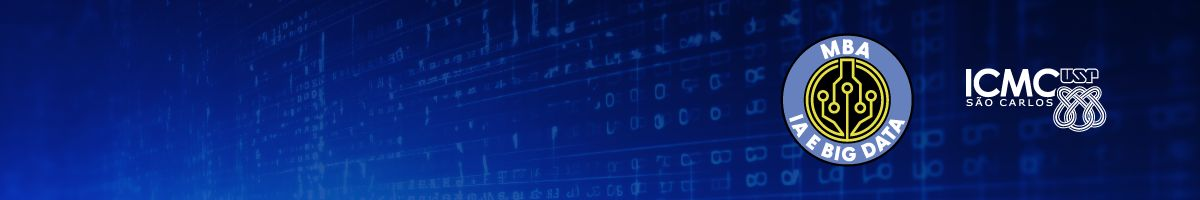

<div style="font-family: Arial; font-size: 16px;  color: #000080;">  

## Teste de Wilcoxon (duas amostras pareadas)


<div style="font-family: Arial; font-size: 16px;  color: #000080;">  

### Exemplo Desempenho de máquinas antes e depois de uma atualização

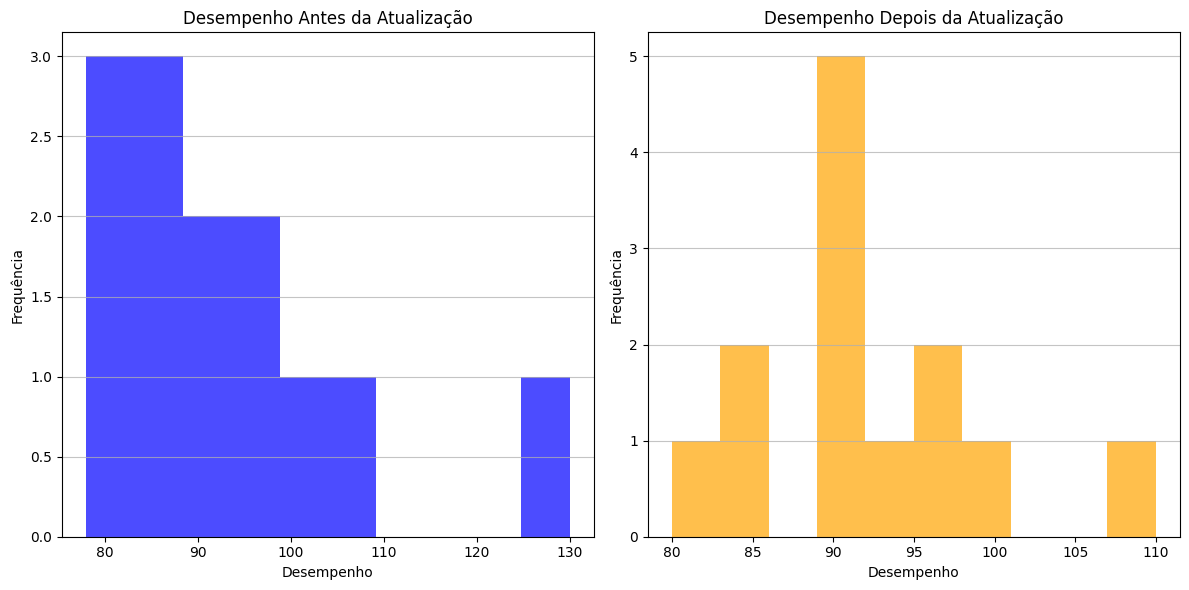

In [10]:
import numpy as np
from scipy.stats import wilcoxon
import matplotlib.pyplot as plt

# Dados de desempenho das máquinas antes e depois da atualização
desempenho_antes = np.array([85, 90, 78, 88, 92, 87, 95, 82, 80, 94, 99, 107, 130])
desempenho_depois = np.array([90, 91, 80, 89, 95, 90, 96, 85, 84, 93, 90, 100, 110])


# Criar histogramas
plt.figure(figsize=(12, 6))

# Histograma para desempenho antes
plt.subplot(1, 2, 1)
plt.hist(desempenho_antes, bins=10, color='blue', alpha=0.7)
plt.title('Desempenho Antes da Atualização')
plt.xlabel('Desempenho')
plt.ylabel('Frequência')
plt.grid(axis='y', alpha=0.75)

# Histograma para desempenho depois
plt.subplot(1, 2, 2)
plt.hist(desempenho_depois, bins=10, color='orange', alpha=0.7)
plt.title('Desempenho Depois da Atualização')
plt.xlabel('Desempenho')
plt.ylabel('Frequência')
plt.grid(axis='y', alpha=0.75)

# Exibir os histogramas
plt.tight_layout()
plt.show()

In [11]:
from scipy.stats import wilcoxon, shapiro

# Teste de Shapiro-Wilk para normalidade
statistic_antes, p_value_antes = shapiro(desempenho_antes)
statistic_depois, p_value_depois = shapiro(desempenho_depois)

# Exibir os resultados do teste de Shapiro-Wilk
print("Teste de Shapiro-Wilk para desempenho antes:")
print("Estatística:", statistic_antes)
print("Valor-p:", p_value_antes)

print("\nTeste de Shapiro-Wilk para desempenho depois:")
print("Estatística:", statistic_depois)
print("Valor-p:", p_value_depois)
# Interpretar os valores-p do teste de Shapiro-Wilk
alpha = 0.05
if p_value_antes < alpha:
    print("\nRejeita a hipótese nula (desempenho antes): Os dados não são normalmente distribuídos.")
else:
    print("\nNão rejeita a hipótese nula (desempenho antes): Os dados são normalmente distribuídos.")

if p_value_depois < alpha:
    print("\nRejeita a hipótese nula (desempenho depois): Os dados não são normalmente distribuídos.")
else:
    print("\nNão rejeita a hipótese nula (desempenho depois): Os dados são normalmente distribuídos.")


Teste de Shapiro-Wilk para desempenho antes:
Estatística: 0.8440407704612446
Valor-p: 0.023876643990693516

Teste de Shapiro-Wilk para desempenho depois:
Estatística: 0.935982245700081
Valor-p: 0.40702123789531053

Rejeita a hipótese nula (desempenho antes): Os dados não são normalmente distribuídos.

Não rejeita a hipótese nula (desempenho depois): Os dados são normalmente distribuídos.


In [12]:
# Teste de Wilcoxon
statistic, p_value = wilcoxon(desempenho_antes, desempenho_depois)

# Exibir os resultados
print("Estatística do teste de Wilcoxon:", statistic)
print("Valor-p:", p_value)

# Interpretar o valor-p
alpha = 0.05
if p_value < alpha:
    print("\nRejeita a hipótese nula: Há uma diferença significativa no desempenho antes e depois da atualização.")
else:
    print("\nNão rejeita a hipótese nula: Não há diferença significativa no desempenho antes e depois da atualização.")


Estatística do teste de Wilcoxon: 38.5
Valor-p: 0.635498046875

Não rejeita a hipótese nula: Não há diferença significativa no desempenho antes e depois da atualização.



<div style="font-family: Arial; font-size: 16px;  color: #000080;">  


## Teste U de Mann-Whitney (duas amostras não-pareadas)



<div style="font-family: Arial; font-size: 16px;  color: #000080;">  

### Exemplo dados de música

In [13]:
import pandas as pd
from scipy.stats import chi2_contingency


# Leitura dos dados de música
df = pd.read_csv('https://raw.githubusercontent.com/cibelerusso/Datasets/main/Music_DB.csv', decimal=',')



In [14]:
df

,Energia,Ao_vivo,Tempo,Falado,Orgânico,Instrumental,Compasso,Dançabilidade,Tom,Duração,Força,Positividade,Modo,Tipo,Music_id,Playlist_name,Album_name,Artista,Music_name
0,0.964,0.1060,167.024,0.0644,0.000071,0.038700,4,0.392,10,200547,0.599722,0.269,0,audio_features,0faXHILILebCGnJBPU6KJJ,Angry,Phobia (Clean Version),Breaking Benjamin,The Diary of Jane - Single Version
1,0.955,0.3800,107.984,0.0653,0.000165,0.000014,4,0.533,8,216733,0.652529,0.550,1,audio_features,2yXyz4NLTZx9CLdXfLTp5E,Angry,Dear Agony,Breaking Benjamin,I Will Not Bow
2,0.939,0.6230,150.184,0.1130,0.000220,0.000000,4,0.524,9,184867,0.631393,0.661,1,audio_features,1Vej0qeQ3ioKwpI6FUbRv1,Angry,Hybrid Theory (Bonus Edition),Linkin Park,Papercut
3,0.969,0.0787,95.136,0.0491,0.001400,0.000001,4,0.492,9,157333,0.601243,0.538,1,audio_features,3K4HG9evC7dg3N0R9cYqk4,Angry,Hybrid Theory (Bonus Edition),Linkin Park,One Step Closer
4,0.970,0.0994,94.952,0.2120,0.030000,0.000000,4,0.512,8,200240,0.639293,0.427,0,audio_features,5egqKwgK5r5rvGD1LrtR7J,Angry,Hybrid Theory (Bonus Edition),Linkin Park,Points of Authority
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7697,0.920,0.0562,100.007,0.0369,0.002120,0.000008,4,0.544,4,272013,0.448745,0.683,0,audio_features,0tJipFCATY8M2WWXXNyJ9p,Nervous,Unholy Savior,Battle Beast,Touch In The Night
7698,0.941,0.0852,124.977,0.0337,0.000026,0.000025,4,0.525,9,177347,0.665350,0.541,0,audio_features,1VKTwfRivDO6neMF6mm9QZ,Nervous,Battle Beast,Battle Beast,Out on the Streets
7699,0.933,0.1740,82.807,0.0774,0.000904,0.000008,4,0.445,4,279587,0.542875,0.517,0,audio_features,3bGMBNy2fhhKYF1haK6pYg,Nervous,Bringer of Pain,Battle Beast,Beyond the Burning Skies
7700,0.886,0.1120,110.021,0.0353,0.000091,0.000431,4,0.506,2,328787,0.630376,0.200,0,audio_features,6NTEk76W6mraayMZV5zhhR,Nervous,Battle Beast,Battle Beast,Into the Heart of Danger


/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


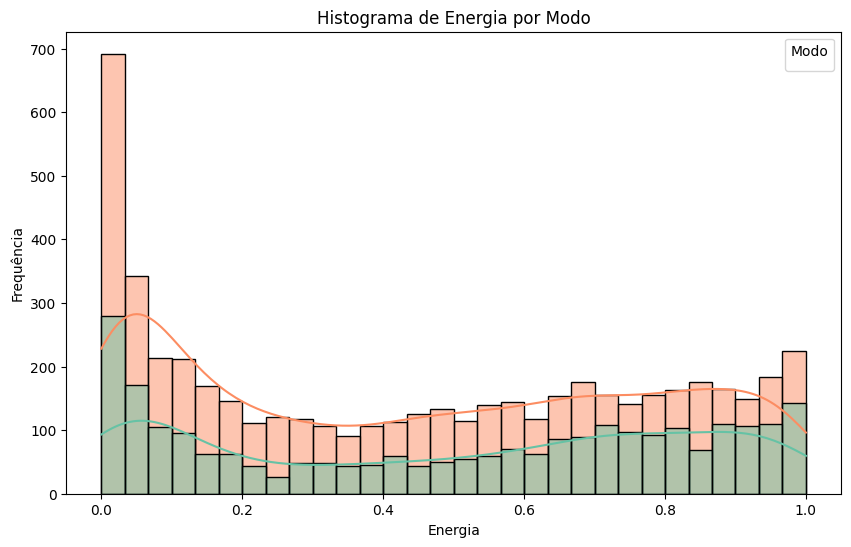

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

# Criando o histograma de Energia por Modo
plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Energia', hue='Modo', kde=True, bins=30, palette='Set2')

# Configurações adicionais
plt.title('Histograma de Energia por Modo')
plt.xlabel('Energia')
plt.ylabel('Frequência')

handles, labels = plt.gca().get_legend_handles_labels()
labels = [modo_labels[int(label)] for label in labels if label.isdigit()]

plt.legend(handles, labels, title='Modo')

plt.show()

In [16]:
import pandas as pd
from scipy.stats import shapiro, ttest_ind, mannwhitneyu

# Dividindo os grupos com base na variável 'Modo'
grupo1 = df[df['Modo'] == 0]['Energia']
grupo2 = df[df['Modo'] == 1]['Energia']

# Teste de normalidade de Shapiro-Wilk para cada grupo
shapiro_grupo1 = shapiro(grupo1)
shapiro_grupo2 = shapiro(grupo2)

print("Teste de Shapiro-Wilk para grupo 1:\n", shapiro_grupo1)
print("Teste de Shapiro-Wilk para grupo 2:\n", shapiro_grupo2)

# Avaliando se os grupos têm distribuição normal (valor p > 0.05 indica normalidade)
if shapiro_grupo1.pvalue > 0.05 and shapiro_grupo2.pvalue > 0.05:
    # Teste t de Student para igualdade das médias (para dados normais)
    t_stat, p_value = ttest_ind(grupo1, grupo2)
    print(f"Teste t de Student: t = {t_stat}, p = {p_value}")
else:
    # Teste de Mann-Whitney (para dados não normais)
    u_stat, p_value = mannwhitneyu(grupo1, grupo2)
    print(f"Teste de Mann-Whitney: U = {u_stat}, p = {p_value}");


Teste de Shapiro-Wilk para grupo 1:
 ShapiroResult(statistic=0.9022087466959591, pvalue=1.405161077828615e-37)
Teste de Shapiro-Wilk para grupo 2:
 ShapiroResult(statistic=0.9085668086534922, pvalue=2.925221572779184e-48)
Teste de Mann-Whitney: U = 7120574.0, p = 1.1835440630469025e-09


/usr/local/lib/python3.10/dist-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5157.
  res = hypotest_fun_out(*samples, **kwds)



<div style="font-family: Arial; font-size: 16px;  color: #000080;">  


## Teste de Kruskall-Wallis (mais de duas amostras não-pareadas)


In [17]:
pd.crosstab(df['Compasso'],columns='Total')

col_0,Total
Compasso,
0,9
1,146
3,955
4,6334
5,258


/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When 

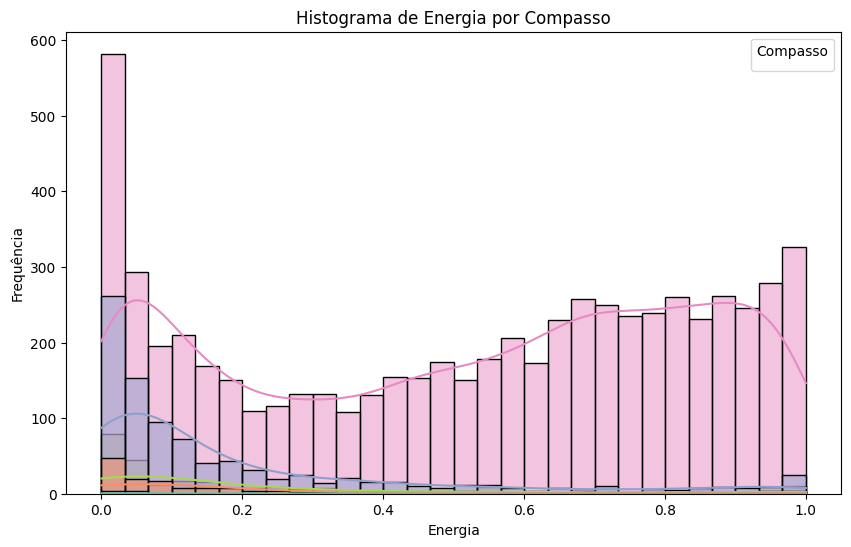

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

# Criando o histograma de Energia por Compasso
plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Energia', hue='Compasso', kde=True, bins=30, palette='Set2')

# Configurações adicionais
plt.title('Histograma de Energia por Compasso')
plt.xlabel('Energia')
plt.ylabel('Frequência')

# Definindo os rótulos personalizados para Compasso (valores de 0 a 5)
compasso_labels = {0: 'Compasso 0', 1: 'Compasso 1', 2: 'Compasso 2', 3: 'Compasso 3', 4: 'Compasso 4', 5: 'Compasso 5'}

# Obtendo os handles e labels atuais da legenda
handles, labels = plt.gca().get_legend_handles_labels()

# Atualizando os rótulos da legenda com base nos valores de Compasso
labels = [compasso_labels[int(label)] for label in labels if label.isdigit()]  # Verifica se o rótulo é um dígito

# Aplicando a nova legenda
plt.legend(handles, labels, title='Compasso')

# Exibindo o gráfico
plt.show()


In [19]:
import pandas as pd
from scipy.stats import shapiro, kruskal

# Lista para armazenar os resultados do teste de Shapiro-Wilk por Compasso
shapiro_results = {}

# Teste de Shapiro-Wilk por grupos de Compasso
for compasso in df['Compasso'].unique():
    grupo = df[df['Compasso'] == compasso]['Energia']
    stat, p_value = shapiro(grupo)
    shapiro_results[compasso] = p_value
    print(f"Teste de Shapiro-Wilk para Compasso {compasso}: p = {p_value}");


Teste de Shapiro-Wilk para Compasso 4: p = 1.5377730089503206e-49
Teste de Shapiro-Wilk para Compasso 3: p = 2.089614412305266e-36
Teste de Shapiro-Wilk para Compasso 5: p = 3.869733564148386e-20
Teste de Shapiro-Wilk para Compasso 1: p = 7.160191769585931e-16
Teste de Shapiro-Wilk para Compasso 0: p = 0.0026627194876170167


/usr/local/lib/python3.10/dist-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 6334.
  res = hypotest_fun_out(*samples, **kwds)


In [20]:
# Se algum grupo não seguir uma distribuição normal, usaremos o teste de Kruskal-Wallis

if all(p > 0.05 for p in shapiro_results.values()):
    print("Todos os grupos seguem uma distribuição normal. Um teste paramétrico poderia ser usado.")
else:
    # Realizando o teste de Kruskal-Wallis para comparar os grupos
    grupos = [df[df['Compasso'] == compasso]['Energia'] for compasso in df['Compasso'].unique()]
    stat, p_value = kruskal(*grupos)
    print(f"Teste de Kruskal-Wallis: H = {stat}, p = {p_value}")


Teste de Kruskal-Wallis: H = 956.0490930201086, p = 1.1938094291403437e-205


In [21]:
# Conclusão
alpha = 0.05
if p_value < alpha:
    print("Conclusão: Há evidências suficientes para rejeitar a hipótese nula.\n As distribuições de 'Energia' são significativamente diferentes entre os grupos de 'Compasso'.")
else:
        print("Conclusão: Não há evidências suficientes para rejeitar a hipótese nula.\n As distribuições de 'Energia' não são significativamente diferentes entre os grupos de 'Compasso'.")

Conclusão: Há evidências suficientes para rejeitar a hipótese nula.
 As distribuições de 'Energia' são significativamente diferentes entre os grupos de 'Compasso'.
